# Gaussian Process Regression (noisy observations) — skeleton

Complete every `TODO`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

## RBF kernel

$$k(x, x') = \sigma^2 \exp\left(-\frac{(x - x')^2}{2\ell^2}\right)$$

In [7]:
def rbf(x1, x2, length_scale=1.0, variance=1.0):
    d = x1[:, None] - x2[None, :]
    # TODO: return the RBF kernel matrix
    return variance*np.exp(-(d)**2/(2*length_scale**2))

## Training data $(X, y)$

$$y = f(X) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma_n^2 I)$$

Joint prior:

$$\begin{bmatrix} y \\ f_* \end{bmatrix} \sim \mathcal{N}\left(0,\; \begin{bmatrix} K(X,X) + \sigma_n^2 I & K(X,X_*) \\ K(X_*,X) & K(X_*,X_*) \end{bmatrix}\right)$$

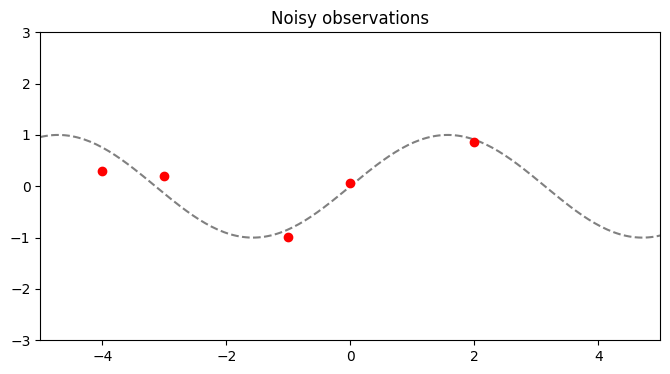

In [8]:
sigma_n = 0.2

X_train = np.array([-4.0, -3.0, -1.0, 0.0, 2.0])
y_train = np.sin(X_train) + sigma_n * np.random.randn(len(X_train))

x = np.linspace(-5, 5, 200)

plt.figure(figsize=(8, 4))
plt.plot(x, np.sin(x), "--", color="gray")
plt.plot(X_train, y_train, "o", color="red")
plt.xlim(-5, 5); plt.ylim(-3, 3)
plt.title("Noisy observations");

## Posterior

$$f_* \mid X_*, X, y \;\sim\; \mathcal{N}\Big(K(X_*, X)\,[K(X, X) + \sigma_n^2 I]^{-1} y,\;\; K(X_*, X_*) - K(X_*, X)\,[K(X, X) + \sigma_n^2 I]^{-1}K(X, X_*)\Big)$$

In [14]:
K.shape

(200, 200)

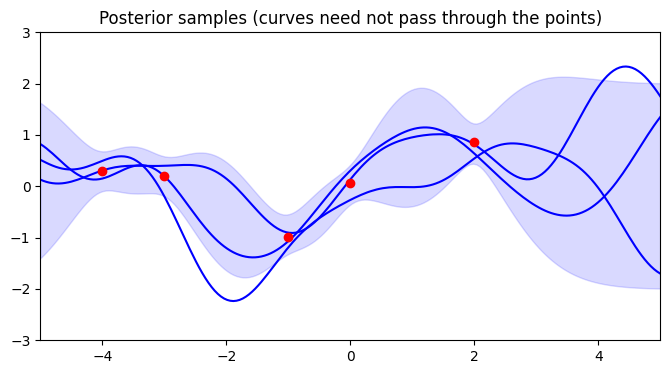

In [15]:
X_test = np.linspace(-5, 5, 200)
K_ss = rbf(X_test, X_test)
K_s  = rbf(X_test, X_train)

# TODO: K(X, X) + sigma_n^2 I   <-- noise goes here
K = rbf(X_train, X_train) + sigma_n**2 * np.eye(len(X_train))

# TODO: posterior mean  (hint: np.linalg.solve instead of inv)
mu_post = K_s@np.linalg.solve(K, y_train)
# TODO: posterior covariance
# cov_post = K_ss - K_s @ np.linalg.solve(K, K_s.T)
cov_post = K_ss - K_s@np.linalg.solve(K, np.eye(K.shape[0]))@K_s.T
std_post = np.sqrt(np.diag(cov_post).clip(0))

f_post = np.random.multivariate_normal(mu_post, cov_post + 1e-8 * np.eye(len(X_test)), size=3)

plt.figure(figsize=(8, 4))
plt.fill_between(X_test, mu_post - 2 * std_post, mu_post + 2 * std_post, color="blue", alpha=0.15)
plt.plot(X_test, f_post.T, color="blue")
plt.plot(X_train, y_train, "o", color="red")
plt.xlim(-5, 5); plt.ylim(-3, 3)
plt.title("Posterior samples (curves need not pass through the points)");

## Predictive for new noisy observations $y_*$

$$\text{cov}(y_*) = \text{cov}(f_*) + \sigma_n^2 I$$

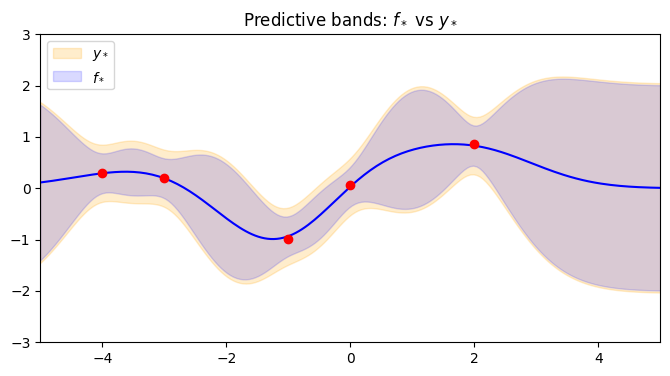

In [21]:
# TODO: predictive std of y* (add the noise variance to the variance of f*)
std_y = np.sqrt(np.diag(cov_post) + sigma_n**2 * np.diag(np.eye(len(X_test))))

plt.figure(figsize=(8, 4))
plt.fill_between(X_test, mu_post - 2 * std_y, mu_post + 2 * std_y, color="orange", alpha=0.2, label="$y_*$")
plt.fill_between(X_test, mu_post - 2 * std_post, mu_post + 2 * std_post, color="blue", alpha=0.15, label="$f_*$")
plt.plot(X_test, mu_post, color="blue")
plt.plot(X_train, y_train, "o", color="red")
plt.xlim(-5, 5); plt.ylim(-3, 3)
plt.legend()
plt.title("Predictive bands: $f_*$ vs $y_*$");

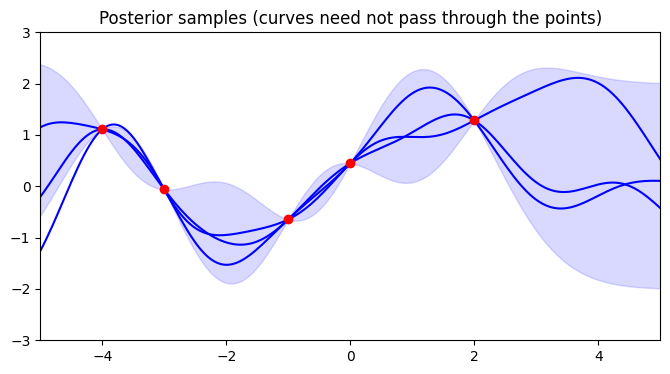

In [27]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

sigma_n = 0.2

np.random.seed(0)
X_train = np.array([-4.0, -3.0, -1.0, 0.0, 2.0])
y_train = np.sin(X_train) + sigma_n * np.random.randn(len(X_train))
X_test = np.linspace(-5, 5, 200)

# TODO: model = fixed RBF kernel (variance 1, length-scale 1) + noise sigma_n^2 via `alpha`
#       (hint: optimizer=None -> hyperparameters are NOT learned, same as the manual version)
gp = GaussianProcessRegressor(kernel=RBF(length_scale=1), optimizer= None)
gp.fit(X_train.reshape(-1, 1), y_train)

mu_post, std_post = gp.predict(X_test.reshape(-1, 1), return_std=True)
f_post = gp.sample_y(X_test.reshape(-1, 1), n_samples=3, random_state=0)  # shape (200, 3)

plt.figure(figsize=(8, 4))
plt.fill_between(X_test, mu_post - 2 * std_post, mu_post + 2 * std_post, color="blue", alpha=0.15)
plt.plot(X_test, f_post, color="blue")   # note: f_post, not f_post.T
plt.plot(X_train, y_train, "o", color="red")
plt.xlim(-5, 5); plt.ylim(-3, 3)
plt.title("Posterior samples (curves need not pass through the points)");